In [14]:
import os, subprocess
import json
import uproot3
import awkward as ak
import numpy as np
from coffea import processor, util, hist
import pickle
import pandas as pd

from plotter import *

In [15]:
lumis = {}
lumis['2016'] = 35.9
lumis['2017'] = 41.5
lumis['2018'] = 59.9

with open('xsec.json') as f:
  xs = json.load(f)

with open('pmap.json') as f:
  pmap = json.load(f)

In [16]:
year = '2017'
nfiles = len(subprocess.getoutput("ls infiles-split/"+year+"*.json").split())
outsum = processor.dict_accumulator()

In [17]:
picklename = 'pickles/'+str(year)+'_templates.pkl'

In [18]:
# Read the histogram from the pickle file

ggf = pickle.load(open(picklename,'rb')).integrate('region','signal-ggf').integrate('systematic','nominal')
vbf = pickle.load(open(picklename,'rb')).integrate('region','signal-vbf').integrate('systematic','nominal')

In [19]:
def significance(s,b):
    if b==0:
        return 0
    z_squared = 2.0*(s+b)*np.log(1.0+1.0*s/b) - 2.0*s
    return np.sqrt(z_squared)

In [20]:
vbf

<Hist (process,pt1,msd1,ddb1) instance at 0x7f15d12d5370>

/opt/conda/lib/python3.8/site-packages/coffea/hist/plot.py:43: RuntimeWarning: All sumw are zero!  Cannot compute meaningful error bars
  warnings.warn(


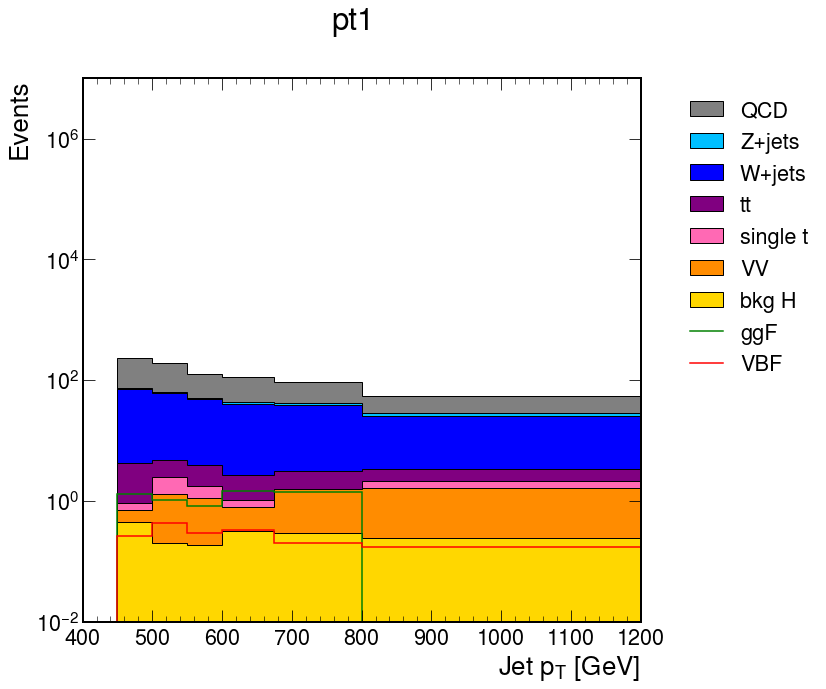

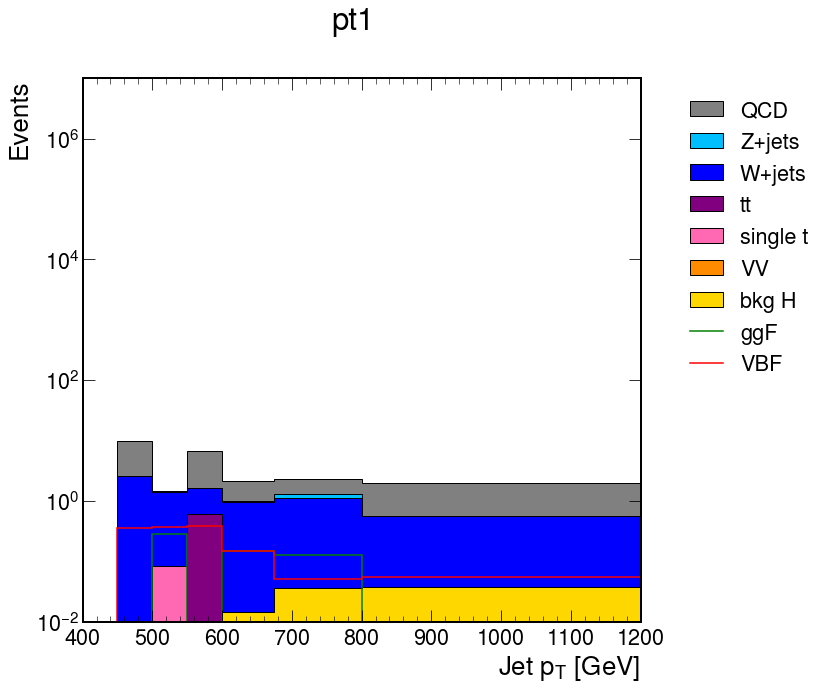

In [21]:
plot_mconly_ggfvbf(ggf.sum('msd1').integrate('ddb1',int_range=slice(0.89,1)),'pt1','pt1')
plot_mconly_ggfvbf(vbf.sum('msd1').integrate('ddb1',int_range=slice(0.89,1)),'pt1','pt1')

/opt/conda/lib/python3.8/site-packages/coffea/hist/plot.py:43: RuntimeWarning: All sumw are zero!  Cannot compute meaningful error bars
  warnings.warn(


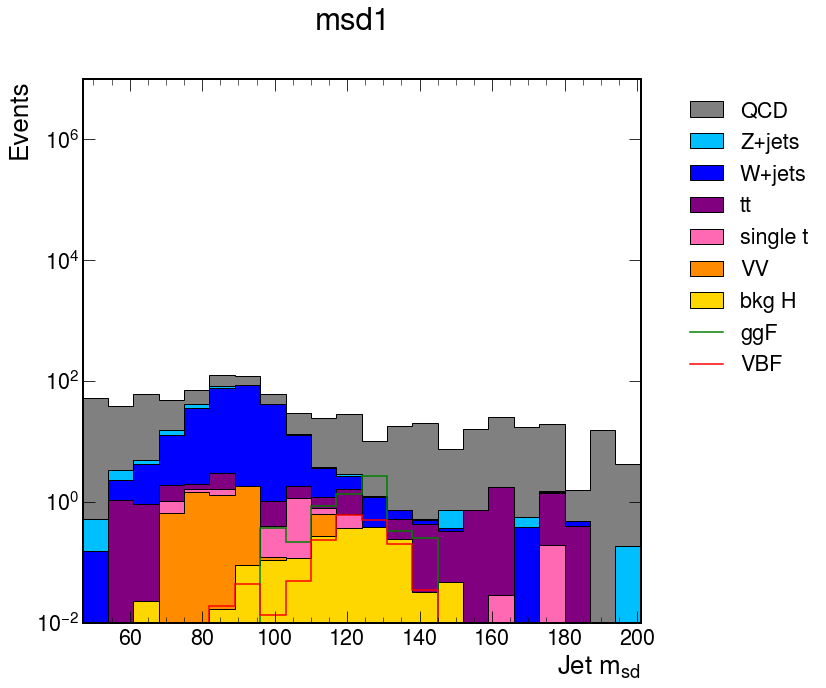

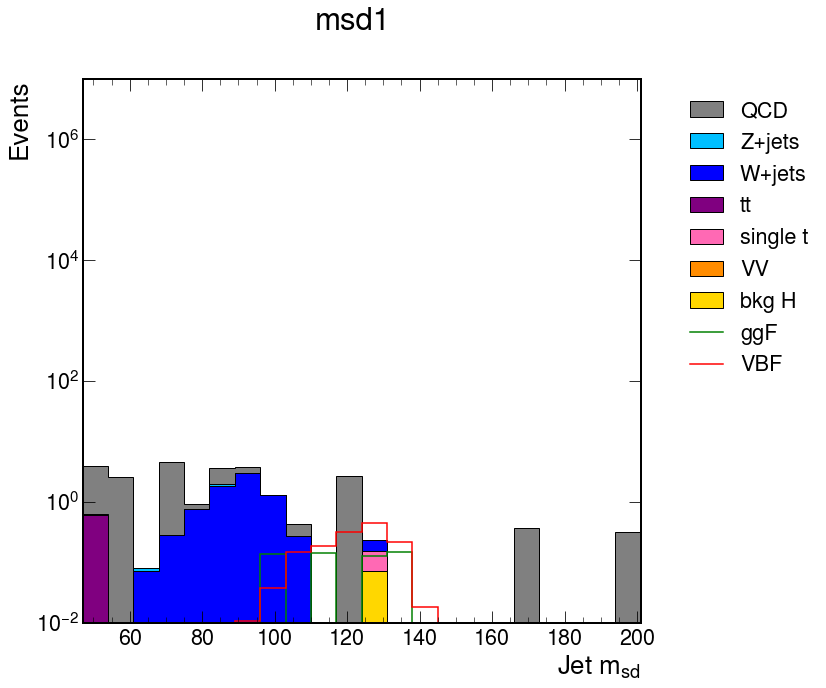

In [22]:
plot_mconly_ggfvbf(ggf.sum('pt1').integrate('ddb1',int_range=slice(0.89,1)),'msd1','msd1')
plot_mconly_ggfvbf(vbf.sum('pt1').integrate('ddb1',int_range=slice(0.89,1)),'msd1','msd1')

In [23]:
# number counting significance only makes sense in the mass window of Higgs
mbb_min = 110
mbb_max = 138

ggf_window=ggf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(0.89,1))
vbf_window=vbf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(0.89,1))

In [24]:
ggf_sr = ggf_window.values()
vbf_sr = vbf_window.values()

In [25]:
# VBF significance
s1 = ggf_sr[('VBF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('ggF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('VBF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('ggF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

0.1644592174362422 0.6029400420079162 0.6249668218843693


In [26]:
# ggF significance
s1 = ggf_sr[('ggF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('VBF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('ggF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('VBF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

# this only makes sense in the mass window of Higgs

0.56747492458802 0.2040444520268816 0.6030438859976356
